# Pre-processing

In [ ]:
!pip install kagglehub timm
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

100%|██████████| 204M/204M [00:01<00:00, 135MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1


In [ ]:
!ls {path}

auto_test  test  train	val


In [ ]:
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms, datasets

base = path

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_full = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val_full   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test_full  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train_full), "| val:", len(val_full), "| test:", len(test_full))
print("classes:", train_full.classes)

train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


### 3 classes
We drop Grade 0 and Grade 1 and keep Grade 2, 3 and 4. The labels are remapped to 0, 1, 2 so the model has 3 outputs:

| Original KL grade | New label |
|---|---|
| 2 | 0 |
| 3 | 1 |
| 4 | 2 |

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from collections import Counter

class_names = ["Grade 2", "Grade 3", "Grade 4"]

class Keep234(Dataset):
    def __init__(self, ds):
        self.ds = ds
        self.idx = [i for i, t in enumerate(ds.targets) if t >= 2]   # keep grades 2,3,4 only
        self.targets = [ds.targets[i] - 2 for i in self.idx]         # remap 2,3,4 -> 0,1,2
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        x, _ = self.ds[self.idx[i]]
        return x, self.targets[i]

train = Keep234(train_full)
val   = Keep234(val_full)
test  = Keep234(test_full)

splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds)
    split_pct = (split_size / total_samples) * 100
    counts = Counter(ds.targets)
    class_dist = {class_names[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}
    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 2446 (69.65%) | Classes: {'Grade 2': '1516 (62.0%)', 'Grade 3': '757 (30.9%)', 'Grade 4': '173 (7.1%)'}
val   | Total:  345 (9.82%) | Classes: {'Grade 2': '212 (61.4%)', 'Grade 3': '106 (30.7%)', 'Grade 4': '27 (7.8%)'}
test  | Total:  721 (20.53%) | Classes: {'Grade 2': '447 (62.0%)', 'Grade 3': '223 (30.9%)', 'Grade 4': '51 (7.1%)'}


In [ ]:
counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (3 * counts[i]) for i in range(3)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])

class weights: [0.54, 1.08, 4.71]


In [ ]:
train_loader = DataLoader(train, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])

batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([1, 0, 1, 0, 0, 0, 0, 0, 1, 0])


### Why does the image have 3 channels instead of 1?
`transforms.Grayscale(3)` copies the single grayscale channel into 3 identical channels (R = G = B), because the pre-trained backbone expects a 3-channel input.

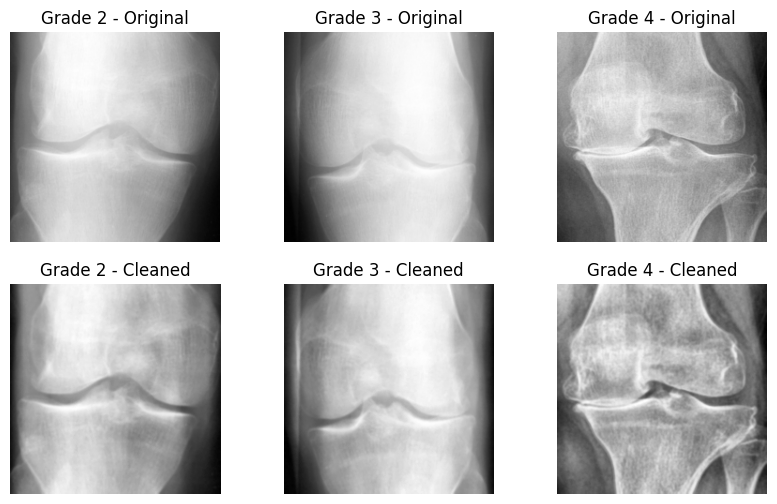

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for j, k in enumerate([2, 3, 4]):
    path_k = train_full.samples[train_full.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][j].imshow(original, cmap="gray"); axes[0][j].set_title(f"Grade {k} - Original"); axes[0][j].axis("off")
    axes[1][j].imshow(cleaned, cmap="gray"); axes[1][j].set_title(f"Grade {k} - Cleaned"); axes[1][j].axis("off")
plt.show()

# Agnostic Code

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (Xception)

## Finetuning

In [ ]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [ ]:
def train_step(model,
               data_loader,
               loss_fn,
               optim,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # iterate through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss.item()
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optim.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optim.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.2f}')

In [ ]:
from sklearn.metrics import f1_score

def test_step(model,
              data_loader,
              loss_fn,
              acc_fn,
              tag = 'Val',
              device = device):

  test_loss, test_acc = 0.0, 0.0
  all_preds, all_labels = [], []

  model.to(device)

  model.eval() # set model to test/ eval mode

  with torch.inference_mode(): # disable gradient tracking: less memory, faster
    for input, label in data_loader:
      input, label = input.to(device), label.to(device)

      # 1. forward
      output = model(input)
      pred = output.argmax(dim=1)

      # 2. calculate the loss
      loss = loss_fn(output, label)
      test_loss += loss.item()
      test_acc += acc_fn(y_true=label, y_pred=pred)

      all_preds.extend(pred.cpu().numpy())
      all_labels.extend(label.cpu().numpy())

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    print(f'{tag} loss: {test_loss:.4f}, {tag} acc: {test_acc:.2f}, {tag} macro-F1: {macro_f1:.4f}')
    return test_acc, macro_f1

In [ ]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions (in %)."""
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [ ]:
import timm
import torch.nn as nn
import torch.optim as optim

# Xception is not in torchvision, so we load the pre-trained one from timm
try:
    model_ft = timm.create_model("legacy_xception", pretrained=True, num_classes=3, drop_rate=0.3)
except Exception as e:
    print("legacy_xception failed, trying 'xception':", e)
    model_ft = timm.create_model("xception", pretrained=True, num_classes=3, drop_rate=0.3)

model_ft = model_ft.to(device)

# the class weights are really used in the loss here
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))

# tweak the entire brain (fineTuning, NOT fixed feature extractor)
optim = optim.Adam(model_ft.parameters(), lr=0.0001)

acc_fn = accuracy_fn

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth


In [ ]:
# Train and eval

import time
from tqdm.auto import tqdm # import for progress bar

since = time.time()

best_model_params_path = 'xception_3class_best.pt'   # to save the AI best ver.
torch.save(model_ft.state_dict(), best_model_params_path)

best_f1 = 0.0
epochs = 25

for epoch in tqdm(range(epochs)):
    print(f'Epoch: {epoch + 1} / {epochs}')
    print('-' * 10)

    train_step(model=model_ft,
               data_loader=train_loader,
               loss_fn=loss_fn,
               optim=optim,
               acc_fn=acc_fn)

    val_acc, val_f1 = test_step(model=model_ft,
                                data_loader=val_loader,
                                loss_fn=loss_fn,
                                acc_fn=acc_fn,
                                tag='Val')

    if val_f1 > best_f1: # the best version is chosen by macro-F1, not accuracy
        best_f1 = val_f1
        torch.save(model_ft.state_dict(), best_model_params_path)
        print(f'Best model saved with val macro-F1: {best_f1:.4f}')

    print()

time_elapsed = time.time() - since
print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Best val macro-F1: {best_f1:.4f}')

# load best model weights
model_ft.load_state_dict(torch.load(best_model_params_path, weights_only=True))

  0%|          | 0/25 [00:00<?, ?it/s]

Epoch: 1 / 25
----------
Train loss: 0.8885, Train acc: 54.97
Val loss: 0.7151, Val acc: 64.34, Val macro-F1: 0.6526
Best model saved with val macro-F1: 0.6526

Epoch: 2 / 25
----------
Train loss: 0.4919, Train acc: 78.17
Val loss: 0.4488, Val acc: 83.93, Val macro-F1: 0.8169
Best model saved with val macro-F1: 0.8169

Epoch: 3 / 25
----------
Train loss: 0.3247, Train acc: 85.34
Val loss: 0.6595, Val acc: 74.07, Val macro-F1: 0.7345

Epoch: 4 / 25
----------
Train loss: 0.2709, Train acc: 88.49
Val loss: 0.6111, Val acc: 78.82, Val macro-F1: 0.7436

Epoch: 5 / 25
----------
Train loss: 0.1840, Train acc: 91.59
Val loss: 0.4410, Val acc: 83.36, Val macro-F1: 0.8197
Best model saved with val macro-F1: 0.8197

Epoch: 6 / 25
----------
Train loss: 0.1688, Train acc: 93.44
Val loss: 0.4520, Val acc: 84.42, Val macro-F1: 0.8421
Best model saved with val macro-F1: 0.8421

Epoch: 7 / 25
----------
Train loss: 0.1273, Train acc: 94.60
Val loss: 0.5372, Val acc: 82.43, Val macro-F1: 0.8266

Ep

<All keys matched successfully>

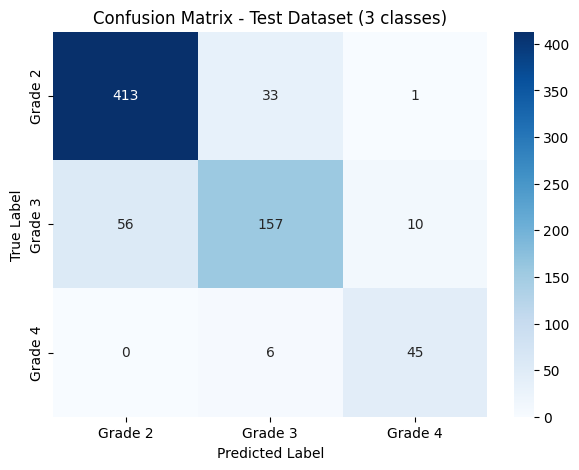

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

# Put model in evaluation mode
model_ft.eval()
all_preds = []
all_labels = []

# Get predictions on test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model_ft(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset (3 classes)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(3)),
    target_names=class_names,
    zero_division=0,
    digits=3
))

print("Confusion matrix:")
print(confusion_matrix(all_labels, all_preds, labels=list(range(3))))

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(all_labels, all_preds) * 100, 2),
    "%"
)

              precision    recall  f1-score   support

     Grade 2      0.881     0.924     0.902       447
     Grade 3      0.801     0.704     0.749       223
     Grade 4      0.804     0.882     0.841        51

    accuracy                          0.853       721
   macro avg      0.828     0.837     0.831       721
weighted avg      0.851     0.853     0.850       721

Confusion matrix:
[[413  33   1]
 [ 56 157  10]
 [  0   6  45]]
Balanced accuracy: 83.68 %


In [ ]:
print("Final test evaluation:")

test_step(
    model=model_ft,
    data_loader=test_loader,
    loss_fn=loss_fn,
    acc_fn=acc_fn,
    tag='Test'
)

Final test evaluation:
Test loss: 0.6129, Test acc: 85.36, Test macro-F1: 0.8308


(85.35805626598466, 0.8307571871689051)

In [ ]:
# Experiment 2: AdamW + Lower Learning Rate

import torch
import torch.nn as nn
import timm

try:
    model_exp2 = timm.create_model(
        "legacy_xception",
        pretrained=True,
        num_classes=3,
        drop_rate=0.3
    )
except Exception:
    model_exp2 = timm.create_model(
        "xception",
        pretrained=True,
        num_classes=3,
        drop_rate=0.3
    )

model_exp2 = model_exp2.to(device)

loss_fn_exp2 = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer_exp2 = torch.optim.AdamW(
    model_exp2.parameters(),
    lr=0.00005,
    weight_decay=0.0001
)

print("Experiment 2 model ready!")

Experiment 2 model ready!


In [ ]:
# Experiment 2: Training

import time
from tqdm.auto import tqdm

best_f1_exp2 = -1.0
best_path_exp2 = "xception_3class_exp2_best.pt"

epochs_exp2 = 25
start_exp2 = time.time()

for epoch in tqdm(range(epochs_exp2)):

    print(f"\nEpoch {epoch+1}/{epochs_exp2}")

    train_step(
        model=model_exp2,
        data_loader=train_loader,
        loss_fn=loss_fn_exp2,
        optim=optimizer_exp2,
        acc_fn=accuracy_fn
    )

    val_acc_exp2, val_f1_exp2 = test_step(
        model=model_exp2,
        data_loader=val_loader,
        loss_fn=loss_fn_exp2,
        acc_fn=accuracy_fn,
        tag="Val Exp2"
    )

    if val_f1_exp2 > best_f1_exp2:
        best_f1_exp2 = val_f1_exp2

        torch.save(
            model_exp2.state_dict(),
            best_path_exp2
        )

        print("Best model saved!")

print("\nTraining completed!")
print(f"Best Validation Macro-F1: {best_f1_exp2:.4f}")
print(f"Training time: {(time.time()-start_exp2)/60:.1f} minutes")

model_exp2.load_state_dict(
    torch.load(
        best_path_exp2,
        map_location=device,
        weights_only=True
    )
)

print("Best Experiment 2 model loaded!")

  0%|          | 0/25 [00:00<?, ?it/s]


Epoch 1/25
Train loss: 1.0161, Train acc: 49.95
Val Exp2 loss: 0.7794, Val Exp2 acc: 66.45, Val Exp2 macro-F1: 0.5254
Best model saved!

Epoch 2/25
Train loss: 0.7068, Train acc: 67.65
Val Exp2 loss: 0.5889, Val Exp2 acc: 74.40, Val Exp2 macro-F1: 0.6960
Best model saved!

Epoch 3/25
Train loss: 0.4658, Train acc: 80.14
Val Exp2 loss: 0.5079, Val Exp2 acc: 80.65, Val Exp2 macro-F1: 0.7969
Best model saved!

Epoch 4/25
Train loss: 0.3644, Train acc: 84.32
Val Exp2 loss: 0.4609, Val Exp2 acc: 79.88, Val Exp2 macro-F1: 0.7976
Best model saved!

Epoch 5/25
Train loss: 0.2955, Train acc: 86.72
Val Exp2 loss: 0.4266, Val Exp2 acc: 81.94, Val Exp2 macro-F1: 0.8072
Best model saved!

Epoch 6/25
Train loss: 0.2238, Train acc: 89.25
Val Exp2 loss: 0.4865, Val Exp2 acc: 79.02, Val Exp2 macro-F1: 0.8016

Epoch 7/25
Train loss: 0.2022, Train acc: 90.94
Val Exp2 loss: 0.4559, Val Exp2 acc: 83.36, Val Exp2 macro-F1: 0.8154
Best model saved!

Epoch 8/25
Train loss: 0.1872, Train acc: 91.58
Val Exp2 l

===== Experiment 2 Results =====
Validation Accuracy: 86.09%
Validation Macro-F1: 0.8478
Validation QWK: 0.8299

Classification Report:
              precision    recall  f1-score   support

     Grade 2       0.86      0.95      0.91       212
     Grade 3       0.85      0.66      0.74       106
     Grade 4       0.86      0.93      0.89        27

    accuracy                           0.86       345
   macro avg       0.86      0.85      0.85       345
weighted avg       0.86      0.86      0.86       345



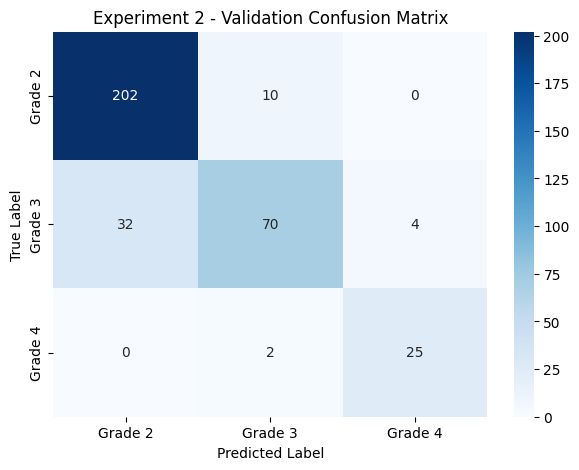

In [ ]:
# Experiment 2: Validation Evaluation
# Accuracy + Macro-F1 + QWK + Confusion Matrix

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)

model_exp2.eval()

preds_exp2 = []
labels_exp2 = []

with torch.inference_mode():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model_exp2(images)
        predictions = outputs.argmax(dim=1)

        preds_exp2.extend(predictions.cpu().tolist())
        labels_exp2.extend(labels.tolist())

# Calculate metrics
accuracy_exp2 = accuracy_score(
    labels_exp2, preds_exp2
) * 100

macro_f1_exp2 = f1_score(
    labels_exp2,
    preds_exp2,
    average="macro",
    zero_division=0
)

qwk_exp2 = cohen_kappa_score(
    labels_exp2,
    preds_exp2,
    labels=[0, 1, 2],
    weights="quadratic"
)

print("===== Experiment 2 Results =====")
print(f"Validation Accuracy: {accuracy_exp2:.2f}%")
print(f"Validation Macro-F1: {macro_f1_exp2:.4f}")
print(f"Validation QWK: {qwk_exp2:.4f}")

print("\nClassification Report:")
print(classification_report(
    labels_exp2,
    preds_exp2,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

cm_exp2 = confusion_matrix(
    labels_exp2,
    preds_exp2,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_exp2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Experiment 2 - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()